In [8]:
# KMeans belong to unsupervised and KNN is to supervised
import numpy as np 
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('tips_data.csv')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,NaN,1.66,Male,No,Sun,NaN,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,NaN,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [ ]:
# feature scaling

# Keep numeric features and remove rows with missing values in those features.
feature_columns = ["total_bill", "tip"]
cluster_data = df[feature_columns].dropna().copy()

# Scaling keeps a feature's units from dominating Euclidean distance.
scaler = StandardScaler()
X = scaler.fit_transform(cluster_data)

n_clusters = 3
print(f"Rows used: {len(X)}; features: {feature_columns}")

Rows used: 243; features: ['total_bill', 'tip']


In [ ]:
def kmeans_from_scratch(X, n_clusters, max_iter=100, tol=1e-4, random_state=42):
    """Cluster rows using Lloyd's K-means algorithm."""
    X = np.asarray(X, dtype=float)

    if X.ndim != 2 or X.shape[0] == 0:
        raise ValueError("X must be a non-empty 2D array")
    if not np.isfinite(X).all():
        raise ValueError("X must contain only finite values")
    if not isinstance(n_clusters, (int, np.integer)) or not 1 <= n_clusters <= len(X):
        raise ValueError("n_clusters must be an integer between 1 and the number of rows")
    if max_iter < 1 or tol < 0:
        raise ValueError("max_iter must be positive and tol must be non-negative")

    rng = np.random.default_rng(random_state)
    centers = X[rng.choice(len(X), size=n_clusters, replace=False)].copy()
    labels = np.full(len(X), -1, dtype=int)

    for _ in range(max_iter):
        distances = np.sum((X[:, np.newaxis, :] - centers[np.newaxis, :, :]) ** 2, axis=2)
        new_labels = np.argmin(distances, axis=1)
        new_centers = centers.copy()

        for cluster_id in range(n_clusters):
            cluster_rows = X[new_labels == cluster_id]
            if len(cluster_rows) > 0:
                new_centers[cluster_id] = cluster_rows.mean(axis=0)

        converged = np.array_equal(new_labels, labels) or np.allclose(
            new_centers, centers, atol=tol, rtol=0
        )
        centers = new_centers
        labels = new_labels
        if converged:
            break

    # Reassign against the final centers, then compute the within-cluster sum of squares.
    distances = np.sum((X[:, np.newaxis, :] - centers[np.newaxis, :, :]) ** 2, axis=2)
    labels = np.argmin(distances, axis=1)
    inertia = float(np.sum((X - centers[labels]) ** 2))
    return labels, centers, inertia

In [5]:
scratch_labels, scratch_centers, scratch_inertia = kmeans_from_scratch(
    X, n_clusters=n_clusters, random_state=42
)

print(f"From-scratch inertia: {scratch_inertia:.2f}")
print("From-scratch centers (standardized features):")
print(scratch_centers)
cluster_data["scratch_cluster"] = scratch_labels
display(cluster_data.head())

From-scratch inertia: 154.24
From-scratch centers (standardized features):
[[ 1.7048903   1.57529729]
 [-0.79083927 -0.80947131]
 [ 0.10215356  0.16374265]]


,total_bill,tip,scratch_cluster
0,16.99,1.01,1
2,21.01,3.50,2
3,23.68,3.31,2
4,24.59,3.61,2
5,25.29,4.71,0


## K-means with scikit-learn

`sklearn.cluster.KMeans` performs the same clustering workflow with a tested library implementation. Cluster numbers are arbitrary, so matching numeric labels between implementations is not required.

In [ ]:
kmeans_model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
library_labels = kmeans_model.fit_predict(X)

comparison = cluster_data.copy()
comparison["sklearn_cluster"] = library_labels

print(f"scikit-learn inertia: {kmeans_model.inertia_:.2f}")
print("scikit-learn centers (standardized features):")
print(kmeans_model.cluster_centers_)
display(comparison.head())

scikit-learn inertia: 154.24
scikit-learn centers (standardized features):
[[-0.79083927 -0.80947131]
 [ 0.10215356  0.16374265]
 [ 1.7048903   1.57529729]]


,total_bill,tip,scratch_cluster,sklearn_cluster
0,16.99,1.01,1,0
2,21.01,3.50,2,1
3,23.68,3.31,2,1
4,24.59,3.61,2,1
5,25.29,4.71,0,2


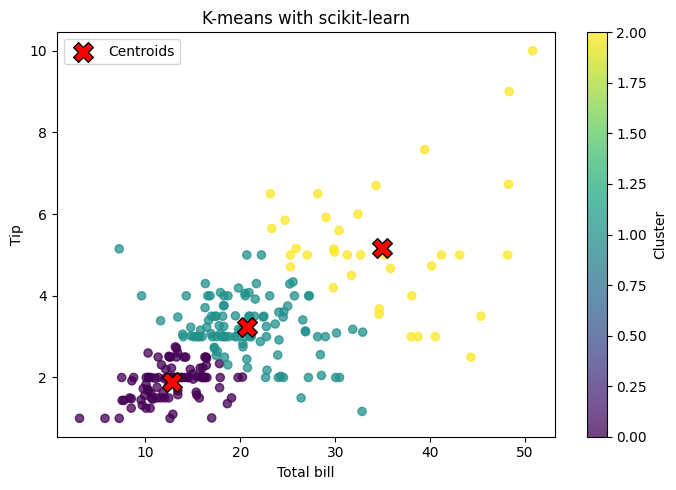

In [ ]:
# kmmeans graph from sci-kit-learn

library_centers_original = scaler.inverse_transform(
    kmeans_model.cluster_centers_
)

plt.figure(figsize=(7, 5))
points = plt.scatter(
    cluster_data["total_bill"],
    cluster_data["tip"],
    c=library_labels,
    cmap="viridis",
    alpha=0.75,
    s=35,
)
plt.scatter(
    library_centers_original[:, 0],
    library_centers_original[:, 1],
    marker="X",
    s=200,
    c="red",
    edgecolors="black",
    label="Centroids",
)

plt.title("K-means with scikit-learn")
plt.xlabel("Total bill")
plt.ylabel("Tip")
plt.colorbar(points, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()

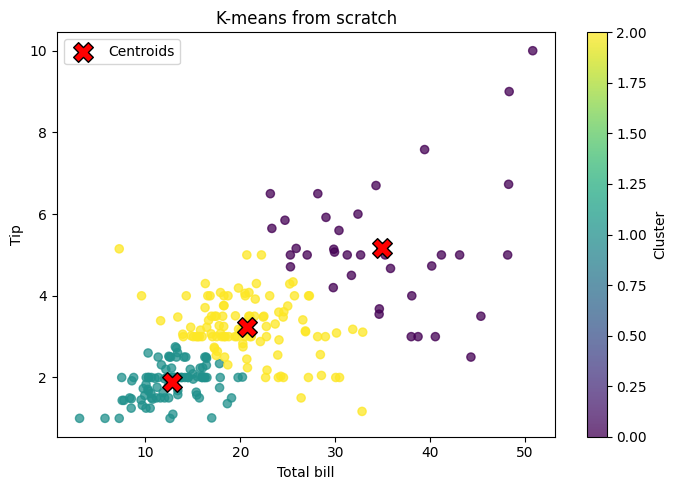

In [11]:
# graph of kmeans from scratch

scratch_centers_original = scaler.inverse_transform(scratch_centers)

plt.figure(figsize=(7, 5))
points = plt.scatter(
    cluster_data["total_bill"],
    cluster_data["tip"],
    c=scratch_labels,
    cmap="viridis",
    alpha=0.75,
    s=35,
)
plt.scatter(
    scratch_centers_original[:, 0],
    scratch_centers_original[:, 1],
    marker="X",
    s=200,
    c="red",
    edgecolors="black",
    label="Centroids",
)

plt.title("K-means from scratch")
plt.xlabel("Total bill")
plt.ylabel("Tip")
plt.colorbar(points, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()